# Kesit İstatistik — Sınıflandırmanın istatistiği

Kurulum: `python -m pip install -r requirements.txt`

Python 3.11+ ve Jupyter/VS Code ile aç. Önce kurulum hücresini, sonra ders hücrelerini çalıştır. Hazır çıktılar doğrulanan çalıştırmadan alınmıştır; kodu değiştirdiğinde hücreyi yeniden çalıştır. Her ders kendi sentetik verisini üretir. İnternet/API/şirket verisi gerektirmez.


## LDA, QDA ve üretici sınıflandırma

Sınıfların kovaryansı farklıysa doğrusal sınır yeterli mi?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** LDA ve QDA’nın aynı testteki olasılık kaybını karşılaştır.

**Yorum sınırı:** QDA daha çok parametre tahmin eder; az veriyle yüksek varyans yaratabilir.

**Alıştırma:** Her sınıfın n değerini 200’den 30’a indir; test sonuçlarının kararlılığını tartış.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


LinearDiscriminantAnalysis {'logloss': 0.3604636813317358, 'AUC': 0.9216326530612245}
QuadraticDiscriminantAnalysis {'logloss': 0.2344054107758948, 'AUC': 0.9648979591836735}


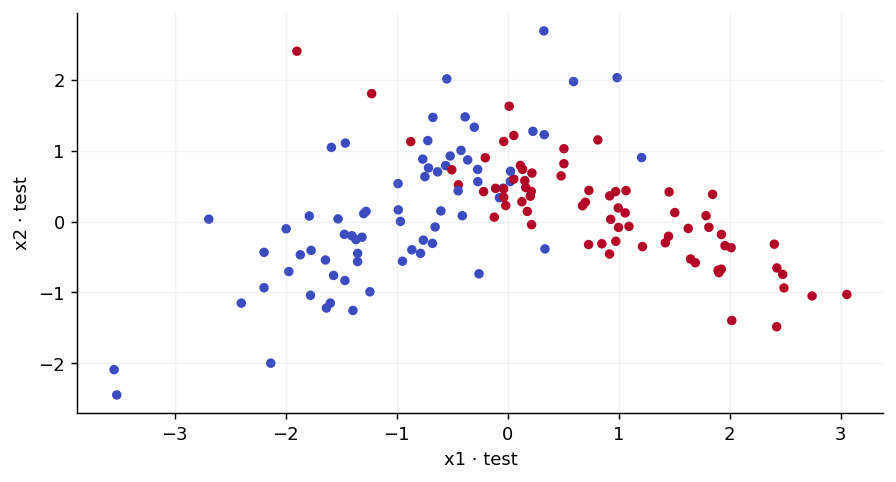

In [97]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
X=np.r_[rng.multivariate_normal([-1,0],[[1,.7],[.7,1]],200),rng.multivariate_normal([1,0],[[1,-.6],[-.6,.5]],200)];y=np.repeat([0,1],200);a,b,c,d=train_test_split(X,y,test_size=.35,stratify=y,random_state=7)
for model in [LinearDiscriminantAnalysis(),QuadraticDiscriminantAnalysis()]:
 model.fit(a,c);p=model.predict_proba(b)[:,1];print(type(model).__name__,{'logloss':log_loss(d,p),'AUC':roc_auc_score(d,p)})
plt.scatter(*b.T,c=d,s=18,cmap='coolwarm');plt.xlabel('x1 · test');plt.ylabel('x2 · test')

## Naive Bayes ve koşullu bağımsızlık

Bağımsızlık varsayımı olasılık güvenini nasıl etkiler?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Aynı sinyalin kopyalarını ekleyerek NB ile lojistiği karşılaştır.

**Yorum sınırı:** Naive Bayes’in koşullu bağımsızlığı sınıf koşulundadır; iyi doğruluk iyi kalibrasyon garantisi değildir.

**Alıştırma:** Gürültülü kopya sayısını 1’den 5’e çıkar; log kaybını izle.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


Gaussian NB {'logloss': 0.37269096080727876, 'Brier': 0.12260758182959022}
Lojistik {'logloss': 0.32423478279079876, 'Brier': 0.10162618279597797}


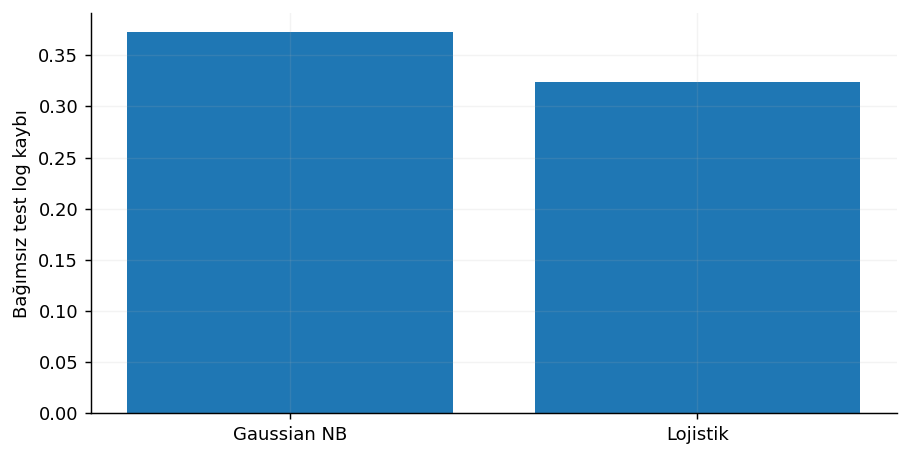

In [98]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

from sklearn.naive_bayes import GaussianNB
X,y=make_classification(n_samples=600,n_features=4,n_informative=2,n_redundant=0,random_state=7);X=np.c_[X,X[:,0]+rng.normal(0,.05,len(X))];a,b,c,d=train_test_split(X,y,test_size=.35,stratify=y,random_state=7);names=[];loss=[]
for name,model in [('Gaussian NB',GaussianNB()),('Lojistik',make_pipeline(StandardScaler(),LogisticRegression()))]:
 model.fit(a,c);p=model.predict_proba(b)[:,1];names.append(name);loss.append(log_loss(d,p));print(name,{'logloss':loss[-1],'Brier':brier_score_loss(d,p)})
plt.bar(names,loss);plt.ylabel('Bağımsız test log kaybı')

## k-en yakın komşu ve boyut etkisi

İlgisiz boyutlar yakın komşuyu neden bozar?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Eklenen gürültü boyutlarıyla test doğruluğunu karşılaştır.

**Yorum sınırı:** Ölçekleme eğitim içinde öğrenilir; tek bölme boyut etkisinin kesin büyüklüğü değildir.

**Alıştırma:** Komşu sayısını 7’den 25’e çıkar; boyut etkisini yeniden değerlendir.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


   ek_gurultu_boyutu  test_dogruluk
0                  0       0.980952
1                  5       0.880952
2                 20       0.833333
3                 60       0.719048


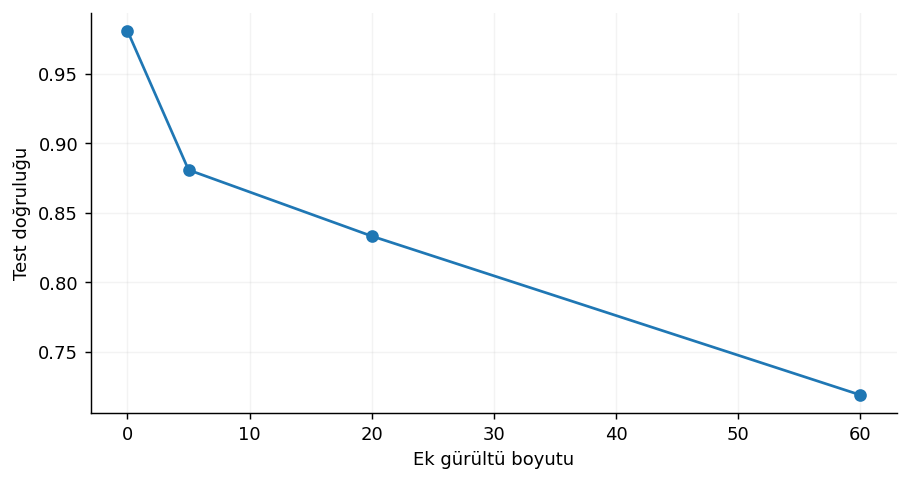

In [99]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

from sklearn.neighbors import KNeighborsClassifier
X,y=make_moons(n_samples=600,noise=.2,random_state=7);dims=[0,5,20,60];scores=[]
for extra in dims:
 xx=np.c_[X,rng.normal(size=(len(X),extra))];a,b,c,d=train_test_split(xx,y,test_size=.35,stratify=y,random_state=7);m=make_pipeline(StandardScaler(),KNeighborsClassifier(7));m.fit(a,c);scores.append(m.score(b,d))
print(pd.DataFrame({'ek_gurultu_boyutu':dims,'test_dogruluk':scores}));plt.plot(dims,scores,'o-');plt.xlabel('Ek gürültü boyutu');plt.ylabel('Test doğruluğu')

## Marj, SVM ve çekirdekler

Doğrusal sınır yerine çekirdek ne kazandırır?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Aynı test noktalarında doğrusal ve RBF kararını karşılaştır.

**Yorum sınırı:** C/gamma testten seçilmez; burada sabit eğitim ayarlarıdır. SVM decision_function kalibre olasılık değildir.

**Alıştırma:** gamma=1 yerine 20 kullan; eğitim/test farkını incele.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


linear {'egitim': 0.8730769230769231, 'test': 0.8642857142857143}
rbf {'egitim': 0.9653846153846154, 'test': 0.9642857142857143}


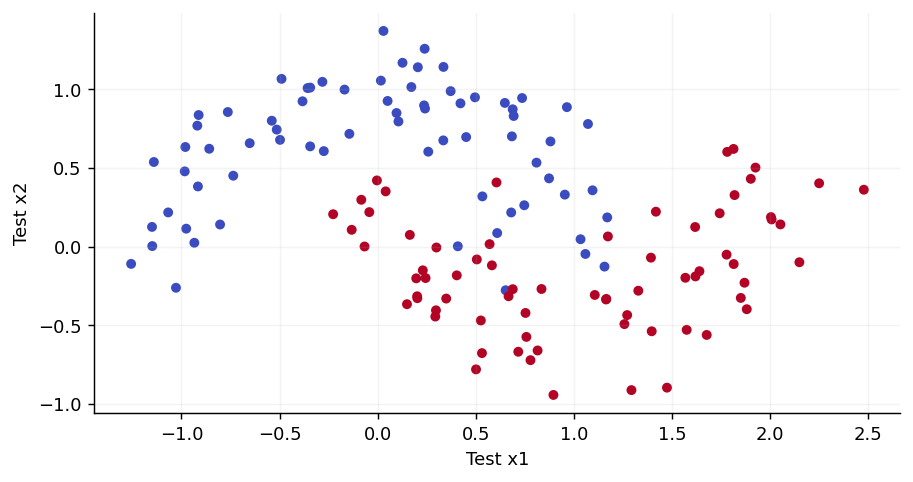

In [100]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

from sklearn.svm import SVC
X,y=make_moons(n_samples=400,noise=.22,random_state=7);a,b,c,d=train_test_split(X,y,test_size=.35,stratify=y,random_state=7)
for kernel in ['linear','rbf']:
 m=make_pipeline(StandardScaler(),SVC(C=1,kernel=kernel,gamma=1));m.fit(a,c);print(kernel,{'egitim':m.score(a,c),'test':m.score(b,d)})
plt.scatter(*b.T,c=d,s=20,cmap='coolwarm');plt.xlabel('Test x1');plt.ylabel('Test x2')